In [1]:
# قدم ۱: ایمپورت کتابخانه‌های لازم
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# تنظیم نمایش اعداد
np.set_printoptions(precision=2, suppress=True)

print("کتابخانه‌ها با موفقیت ایمپورت شدند ✅")

کتابخانه‌ها با موفقیت ایمپورت شدند ✅


In [2]:
# قدم ۲: تولید داده مصنوعی
np.random.seed(42)   # برای تکرارپذیری نتایج

X = np.column_stack([
    np.linspace(50, 200, 100),           # متراژ خانه (50 تا 200 متر)
    np.random.randint(1, 5, 100),        # تعداد اتاق (1 تا 4)
    np.random.randint(1, 20, 100)        # سن بنا (1 تا 19 سال)
])

y = (50 * X[:, 0]          # اثر متراژ: هر متر ۵۰ واحد قیمت
     + 2000 * X[:, 1]      # اثر هر اتاق: ۲۰۰۰ واحد
     - 100 * X[:, 2]       # اثر سن: هر سال ۱۰۰ واحد کاهش
     + np.random.normal(0, 500, 100))  # نویز تصادفی

print("شکل X:", X.shape)
print("شکل y:", y.shape)
print("چند نمونه از داده:")
print(X[:5])
print("چند نمونه از قیمت:")
print(y[:5])

شکل X: (100, 3)
شکل y: (100,)
چند نمونه از داده:
[[50.    3.   18.  ]
 [51.52  4.   12.  ]
 [53.03  1.    2.  ]
 [54.55  3.   10.  ]
 [56.06  3.    4.  ]]
چند نمونه از قیمت:
[6368.63 9302.52 4028.51 7316.03 8946.39]


        متراژ  تعداد اتاق  سن بنا      قیمت
count  100.00      100.00  100.00    100.00
mean   125.00        2.64    9.22  10635.21
std     43.96        1.11    5.16   3217.85
min     50.00        1.00    1.00   3133.66
25%     87.50        2.00    5.00   8318.17
50%    125.00        3.00    9.00  10772.13
75%    162.50        4.00   13.00  12835.35
max    200.00        4.00   19.00  17169.73

همبستگی بین ویژگی‌ها و قیمت:
            متراژ  تعداد اتاق  سن بنا   قیمت
متراژ       1.000      -0.055  -0.105  0.659
تعداد اتاق -0.055       1.000  -0.134  0.679
سن بنا     -0.105      -0.134   1.000 -0.333
قیمت        0.659       0.679  -0.333  1.000


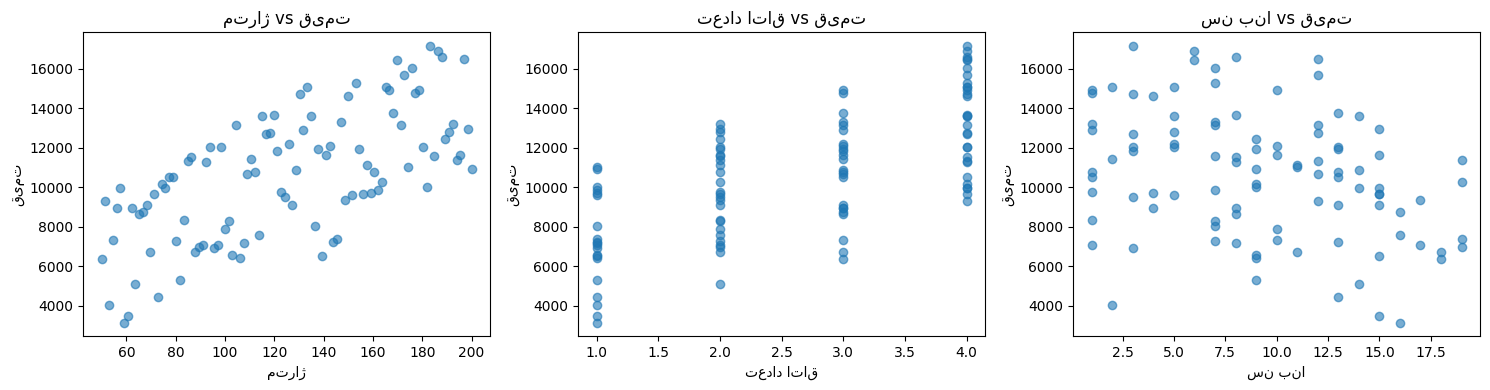

In [3]:
# قدم ۳: ساخت DataFrame و بررسی آماری
df = pd.DataFrame(X, columns=['متراژ', 'تعداد اتاق', 'سن بنا'])
df['قیمت'] = y

print(df.describe().round(2))
print("\nهمبستگی بین ویژگی‌ها و قیمت:")
print(df.corr().round(3))

# رسم نمودار پراکندگی ویژگی‌ها در برابر قیمت
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(['متراژ', 'تعداد اتاق', 'سن بنا']):
    axes[i].scatter(df[col], df['قیمت'], alpha=0.6)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('قیمت')
    axes[i].set_title(f'{col} vs قیمت')
plt.tight_layout()
plt.show()

In [4]:
# قدم ۴: تقسیم داده به ۸۰٪ آموزش و ۲۰٪ آزمون
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("تعداد نمونه آموزش:", X_train.shape[0])
print("تعداد نمونه آزمون:", X_test.shape[0])

تعداد نمونه آموزش: 80
تعداد نمونه آزمون: 20


In [5]:
# قدم ۵: آموزش مدل رگرسیون خطی
model = LinearRegression()
model.fit(X_train, y_train)

print("مدل با موفقیت آموزش دید ✅")
print("ضرایب (Coefficients):", model.coef_.round(2))
print("عرض از مبدا (Intercept):", round(model.intercept_, 2))

مدل با موفقیت آموزش دید ✅
ضرایب (Coefficients): [  50.98 2037.85 -102.31]
عرض از مبدا (Intercept): -168.01


In [6]:
# قدم ۶: پیش‌بینی و محاسبه معیارها
y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
mse_test  = mean_squared_error(y_test, y_pred_test)
r2_train  = r2_score(y_train, y_pred_train)
r2_test   = r2_score(y_test, y_pred_test)

print(f"MSE آموزش: {mse_train:,.0f}")
print(f"MSE آزمون: {mse_test:,.0f}")
print(f"R² آموزش: {r2_train:.3f}")
print(f"R² آزمون: {r2_test:.3f}")

MSE آموزش: 254,983
MSE آزمون: 260,492
R² آموزش: 0.975
R² آزمون: 0.974


ماتریس همبستگی ویژگی‌ها:
            متراژ  تعداد اتاق  سن بنا
متراژ       1.000      -0.055  -0.105
تعداد اتاق -0.055       1.000  -0.134
سن بنا     -0.105      -0.134   1.000


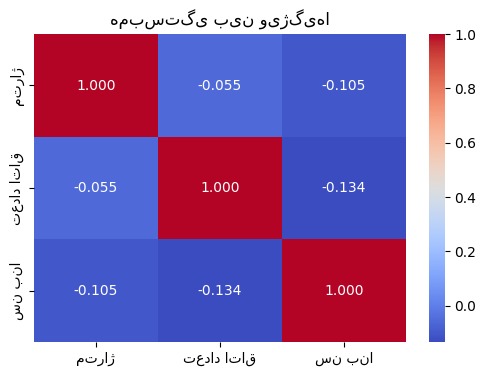


مقدار VIF برای هر ویژگی:
        ویژگی   VIF
0       متراژ  1.02
1  تعداد اتاق  1.02
2      سن بنا  1.03


In [7]:
# قدم ۷: بررسی همبستگی بین ویژگی‌ها (Multicollinearity)
corr_matrix = pd.DataFrame(X, columns=['متراژ', 'تعداد اتاق', 'سن بنا']).corr()
print("ماتریس همبستگی ویژگی‌ها:")
print(corr_matrix.round(3))

# رسم Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f')
plt.title('همبستگی بین ویژگی‌ها')
plt.show()

# محاسبه VIF (Variance Inflation Factor)
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    vif_data = pd.DataFrame()
    vif_data['ویژگی'] = ['متراژ', 'تعداد اتاق', 'سن بنا']
    vif_data['VIF'] = [variance_inflation_factor(X, i) for i in range(X.shape[1])]
    print("\nمقدار VIF برای هر ویژگی:")
    print(vif_data.round(2))
except ImportError:
    print("برای VIF دستور زیر را اجرا کنید: !pip install statsmodels")

In [8]:
# قدم ۸: مقایسه ضرایب مدل با ضرایب واقعی
coef_df = pd.DataFrame({
    'ویژگی': ['متراژ', 'تعداد اتاق', 'سن بنا'],
    'ضریب واقعی': [50, 2000, -100],
    'ضریب یادگرفته‌شده': model.coef_.round(2),
    'اختلاف': (model.coef_ - np.array([50, 2000, -100])).round(2)
})
print(coef_df)
print("\nعرض از مبدا واقعی: 0")
print("عرض از مبدا یادگرفته‌شده:", round(model.intercept_, 2))

        ویژگی  ضریب واقعی  ضریب یادگرفته‌شده  اختلاف
0       متراژ          50              50.98    0.98
1  تعداد اتاق        2000            2037.85   37.85
2      سن بنا        -100            -102.31   -2.31

عرض از مبدا واقعی: 0
عرض از مبدا یادگرفته‌شده: -168.01
